# 01 — Jump model router (prototype)

Regime router trained on **real daily data**. It uses a statistical jump model (JM) following
Shu, Yu & Mulvey (2024), `papers/shu_yu_mulvey2024_2402.05272.pdf`.

**Setup**
- Market signal: SPY excess return over T-bills (BIL)
- Features (paper, Table 2): EWM downside deviation (halflife 10), EWM Sortino ratio (halflife 20 and 60)
- Model: discrete JM with 2 states, jump penalty $\lambda = 50$ (the paper's typical value); continuous JM for soft probabilities
- Train: 2013 to 2021. Validation: 2022 to 2024-08. The test period is never loaded here (`regime_moe.data.real` cuts it off)

**Two kinds of labels**
- *In-sample* (`labels_`): fitted with the whole training window, including the future. Only for analysis.
- *Online* (`predict_online`): day $t$ uses only data up to $t$. This is what a router can actually use.
  Within the training window the model *parameters* still come from the full training window, so only the validation period is truly out of sample.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from jumpmodels.jump import JumpModel
from jumpmodels.preprocess import DataClipperStd, StandardScalerPD

pd.set_option("display.float_format", "{:.3f}".format)
plt.rcParams["figure.figsize"] = (13, 4.5)

## Config

In [2]:
from regime_moe.config import load_config
from regime_moe.data.real import load_prices

DATA = load_config().data               # configs/defaults/data.toml
ASSETS, CASH = DATA.assets, DATA.cash
TRAIN_START, TRAIN_END = DATA.train_start, DATA.train_end
VAL_START, VAL_END = DATA.val_start, DATA.val_end

N_REGIMES = 2
JUMP_PENALTY = 50.0
REGIME_NAMES = {0: "Bull", 1: "Bear"}
REGIME_COLORS = {"Bull": "tab:green", "Neutral": "tab:orange", "Bear": "tab:red"}

## Data

In [3]:
px = load_prices(ASSETS + [CASH], DATA).dropna()  # ends at VAL_END; test period is cut off
rets = px.pct_change().dropna()
excess = rets["SPY"] - rets[CASH]
print(f"{rets.index[0].date()} .. {rets.index[-1].date()}, {len(rets)} days")
rets.tail()

2012-01-04 .. 2024-08-30, 3185 days


Ticker,SPY,TLT,GLD,DBC,BIL
Date,,,,,
2024-08-26,-0.002,-0.003,0.003,0.010,0.000
2024-08-27,0.001,-0.002,0.003,-0.005,0.000
2024-08-28,-0.006,-0.001,-0.007,-0.012,0.000
2024-08-29,0.000,-0.003,0.005,0.011,0.000
2024-08-30,0.010,-0.011,-0.007,-0.011,0.001


## Features (Shu, Yu & Mulvey 2024, Table 2)

With excess return $R_t$ and EWM expectation $E_h$ at halflife $h$:
- downside deviation $DD_h = \sqrt{E_h[R_t^2 \, 1\{R_t < 0\}]}$
- Sortino ratio $S_h = E_h[R_t] / DD_h$

In [4]:
def ewm_dd(r: pd.Series, hl: float) -> pd.Series:
    return np.sqrt((r.clip(upper=0) ** 2).ewm(halflife=hl).mean())


def ewm_sortino(r: pd.Series, hl: float) -> pd.Series:
    return r.ewm(halflife=hl).mean() / ewm_dd(r, hl)


features = pd.DataFrame({
    "DD_10": ewm_dd(excess, 10),
    "Sortino_20": ewm_sortino(excess, 20),
    "Sortino_60": ewm_sortino(excess, 60),
}).loc[TRAIN_START:]

X_train_raw = features.loc[:TRAIN_END]

# clip and standardize with statistics from the training window only
clipper, scaler = DataClipperStd(mul=3.0), StandardScalerPD()
X_train = scaler.fit_transform(clipper.fit_transform(X_train_raw))
X_all = scaler.transform(clipper.transform(features))
features.describe()

,DD_10,Sortino_20,Sortino_60
count,2936.000,2936.000,2936.000
mean,0.006,0.142,0.103
std,0.004,0.184,0.093
min,0.001,-0.369,-0.179
25%,0.004,0.020,0.043
50%,0.005,0.145,0.106
75%,0.008,0.250,0.169
max,0.044,1.492,0.587


## Fit the jump model (discrete, 2 states)

In [5]:
jm = JumpModel(n_components=N_REGIMES, jump_penalty=JUMP_PENALTY, cont=False, random_state=0)
jm.fit(X_train, ret_ser=excess.loc[X_train.index], sort_by="cumret")

labels_insample = jm.labels_                      # train window, uses future data
labels_online = jm.predict_online(X_all)          # full period, causal

print("state means of SPY excess return (daily):", np.round(jm.ret_, 5))
print("state vols (daily):", np.round(jm.vol_, 4))
pd.DataFrame(jm.centers_, columns=X_train.columns, index=[REGIME_NAMES[k] for k in range(N_REGIMES)])

state means of SPY excess return (daily): [ 0.00081 -0.0002 ]
state vols (daily): [0.0071 0.0195]


,DD_10,Sortino_20,Sortino_60
Bull,-0.329,0.226,0.288
Bear,1.576,-1.083,-1.379


## Regime plot (like Fig. 4 in jrfm-13)

SPY price colored by regime. Top: in-sample labels (train only). Bottom: online labels over train + validation; the shaded area is the validation period.

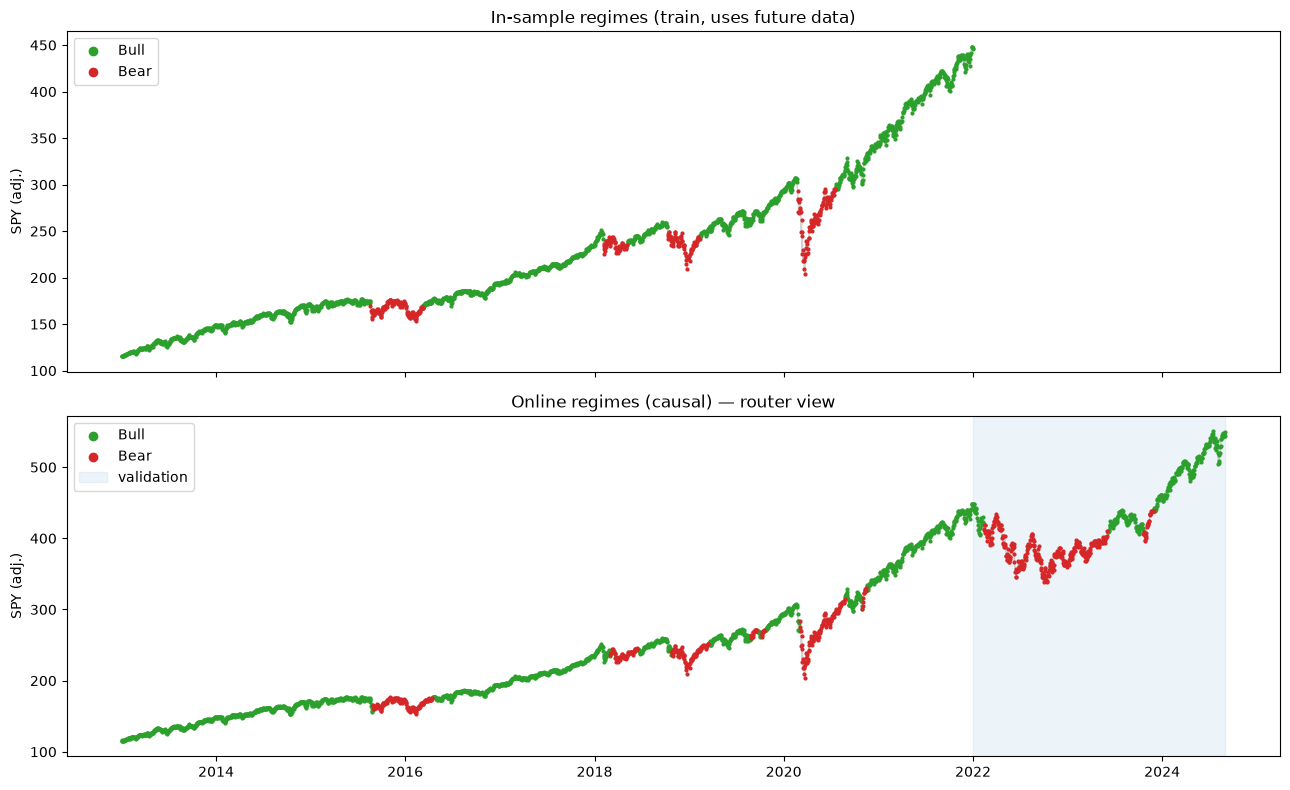

In [6]:
def plot_regimes(price: pd.Series, labels: pd.Series, title: str, ax, val_start=None, names=REGIME_NAMES):
    p = price.loc[labels.index]
    ax.plot(p.index, p.values, color="lightgrey", lw=1, zorder=1)
    for k in sorted(labels.unique()):
        m = labels == k
        ax.scatter(p.index[m], p.values[m], s=4, color=REGIME_COLORS[names[k]], label=names[k], zorder=2)
    if val_start is not None:
        ax.axvspan(pd.Timestamp(val_start), p.index[-1], color="tab:blue", alpha=0.08, label="validation")
    ax.set_title(title)
    ax.set_ylabel("SPY (adj.)")
    ax.legend(loc="upper left", markerscale=3)


fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
plot_regimes(px["SPY"], labels_insample, "In-sample regimes (train, uses future data)", axes[0])
plot_regimes(px["SPY"], labels_online, "Online regimes (causal) — router view", axes[1], val_start=VAL_START)
plt.tight_layout()

## Regime summaries (like Table 3 in jrfm-13, plus per asset)

In [7]:
def episodes(labels: pd.Series) -> pd.DataFrame:
    # one row per contiguous run of the same regime
    run_id = (labels != labels.shift()).cumsum()
    g = labels.groupby(run_id)
    return pd.DataFrame({"regime": g.first(), "start": g.apply(lambda s: s.index[0]), "days": g.size()})


def regime_summary(labels: pd.Series, rets: pd.DataFrame, cash: str = CASH) -> pd.DataFrame:
    ep = episodes(labels)
    years = len(labels) / 252
    rows = {}
    for k in sorted(labels.unique()):
        d = labels.index[labels == k]
        r = rets.loc[d]
        row = {
            "share of days": len(d) / len(labels),
            "episodes": int((ep.regime == k).sum()),
            "mean duration (days)": ep.loc[ep.regime == k, "days"].mean(),
            "median duration (days)": ep.loc[ep.regime == k, "days"].median(),
        }
        for a in ASSETS:
            ex = r[a] - r[cash]
            row[f"{a} ann. ret"] = r[a].mean() * 252
            row[f"{a} ann. vol"] = r[a].std() * np.sqrt(252)
            row[f"{a} Sharpe"] = ex.mean() / ex.std() * np.sqrt(252)
        rows[REGIME_NAMES.get(k, k)] = row
    print(f"regime switches per year: {(len(ep) - 1) / years:.2f}")
    return pd.DataFrame(rows)


def transition_matrix(labels: pd.Series) -> pd.DataFrame:
    names = [REGIME_NAMES.get(k, k) for k in sorted(labels.unique())]
    ct = pd.crosstab(labels.shift().dropna().astype(int), labels.iloc[1:])
    tm = ct.div(ct.sum(axis=1), axis=0)
    tm.index, tm.columns = names, names
    return tm

In [8]:
print("IN-SAMPLE, train window")
regime_summary(labels_insample, rets)

IN-SAMPLE, train window
regime switches per year: 0.89


,Bull,Bear
share of days,0.828,0.172
episodes,5.000,4.000
mean duration (days),375.200,97.750
median duration (days),368.000,93.000
SPY ann. ret,0.210,-0.042
SPY ann. vol,0.113,0.309
SPY Sharpe,1.815,-0.162
TLT ann. ret,0.030,0.177
TLT ann. vol,0.124,0.185
TLT Sharpe,0.207,0.913


In [9]:
print("ONLINE, train window")
regime_summary(labels_online.loc[:TRAIN_END], rets)

ONLINE, train window
regime switches per year: 1.78


,Bull,Bear
share of days,0.788,0.212
episodes,9.000,8.000
mean duration (days),198.556,60.000
median duration (days),92.000,38.500
SPY ann. ret,0.135,0.284
SPY ann. vol,0.124,0.265
SPY Sharpe,1.049,1.042
TLT ann. ret,0.045,0.096
TLT ann. vol,0.124,0.175
TLT Sharpe,0.325,0.501


In [10]:
print("ONLINE, validation window (out of sample)")
regime_summary(labels_online.loc[VAL_START:], rets)

ONLINE, validation window (out of sample)
regime switches per year: 1.51


,Bull,Bear
share of days,0.468,0.532
episodes,3.000,2.000
mean duration (days),104.333,178.000
median duration (days),96.000,178.000
SPY ann. ret,0.148,0.048
SPY ann. vol,0.127,0.217
SPY Sharpe,0.794,0.098
TLT ann. ret,-0.156,-0.078
TLT ann. vol,0.159,0.202
TLT Sharpe,-1.278,-0.522


In [11]:
print("Transition matrix, in-sample (rows: from, cols: to)")
display(transition_matrix(labels_insample))
print("Transition matrix, online train")
display(transition_matrix(labels_online.loc[:TRAIN_END]))

Transition matrix, in-sample (rows: from, cols: to)


,Bull,Bear
Bull,0.998,0.002
Bear,0.010,0.990


Transition matrix, online train


,Bull,Bear
Bull,0.996,0.004
Bear,0.017,0.983


## Online vs. in-sample: how late does the router notice?

For each in-sample switch in the training window: days until the online labels switch to the same regime (searched within 60 days).

In [12]:
def detection_delays(insample: pd.Series, online: pd.Series, max_lag: int = 60) -> pd.DataFrame:
    online = online.loc[insample.index]
    sw = insample.index[(insample != insample.shift()) & insample.shift().notna()]
    pos = {d: i for i, d in enumerate(online.index)}
    rows = []
    for d in sw:
        i, target = pos[d], insample.loc[d]
        window = online.iloc[i : i + max_lag + 1]
        hit = np.flatnonzero(window.values == target)
        rows.append({"switch date": d.date(), "to": REGIME_NAMES.get(target, target),
                     "delay (days)": int(hit[0]) if len(hit) else np.nan})
    return pd.DataFrame(rows)


delays = detection_delays(labels_insample, labels_online)
agree = (labels_online.loc[labels_insample.index] == labels_insample).mean()
print(f"agreement online vs in-sample (train): {agree:.1%}")
print(f"median delay: {delays['delay (days)'].median():.0f} days, mean: {delays['delay (days)'].mean():.1f}, "
      f"not detected within 60d: {delays['delay (days)'].isna().sum()} of {len(delays)}")
delays

agreement online vs in-sample (train): 92.1%
median delay: 20 days, mean: 17.6, not detected within 60d: 0 of 8


,switch date,to,delay (days)
0,2015-08-20,Bear,6
1,2016-03-11,Bull,23
2,2018-02-05,Bear,18
3,2018-05-09,Bull,27
4,2018-10-10,Bear,11
5,2019-02-12,Bull,23
6,2020-02-24,Bear,7
7,2020-07-20,Bull,26


## Jump penalty sensitivity

$\lambda = 0$ is plain k-means; larger $\lambda$ gives fewer, longer regimes, but also later detection.

In [13]:
rows = []
for lam in [0, 5, 10, 25, 50, 100, 200]:
    m = JumpModel(n_components=N_REGIMES, jump_penalty=lam, cont=False, random_state=0)
    m.fit(X_train, ret_ser=excess.loc[X_train.index], sort_by="cumret")
    on = m.predict_online(X_all)
    d = detection_delays(m.labels_, on)
    rows.append({
        "lambda": lam,
        "switches/yr in-sample": (len(episodes(m.labels_)) - 1) / (len(m.labels_) / 252),
        "switches/yr online (train)": (len(episodes(on.loc[:TRAIN_END])) - 1) / (len(on.loc[:TRAIN_END]) / 252),
        "switches/yr online (val)": (len(episodes(on.loc[VAL_START:])) - 1) / (len(on.loc[VAL_START:]) / 252),
        "bear share in-sample": (m.labels_ == 1).mean(),
        "median delay (days)": d["delay (days)"].median(),
    })
pd.DataFrame(rows).set_index("lambda")

,switches/yr in-sample,switches/yr online (train),switches/yr online (val),bear share in-sample,median delay (days)
lambda,,,,,
0,15.340,15.340,12.807,0.382,0.000
5,3.112,4.669,3.767,0.316,4.000
10,2.446,3.112,2.260,0.300,7.000
25,1.334,1.779,2.260,0.235,16.500
50,0.889,1.779,1.507,0.172,20.500
100,0.445,0.667,0.753,0.551,44.000
200,0.445,0.667,0.753,0.550,NaN


## Continuous jump model: soft probabilities (= soft gate)

Aydinhan, Kolm, Mulvey & Shu (2024): the state becomes a probability vector. These would be the MoE gating weights $p_t$.

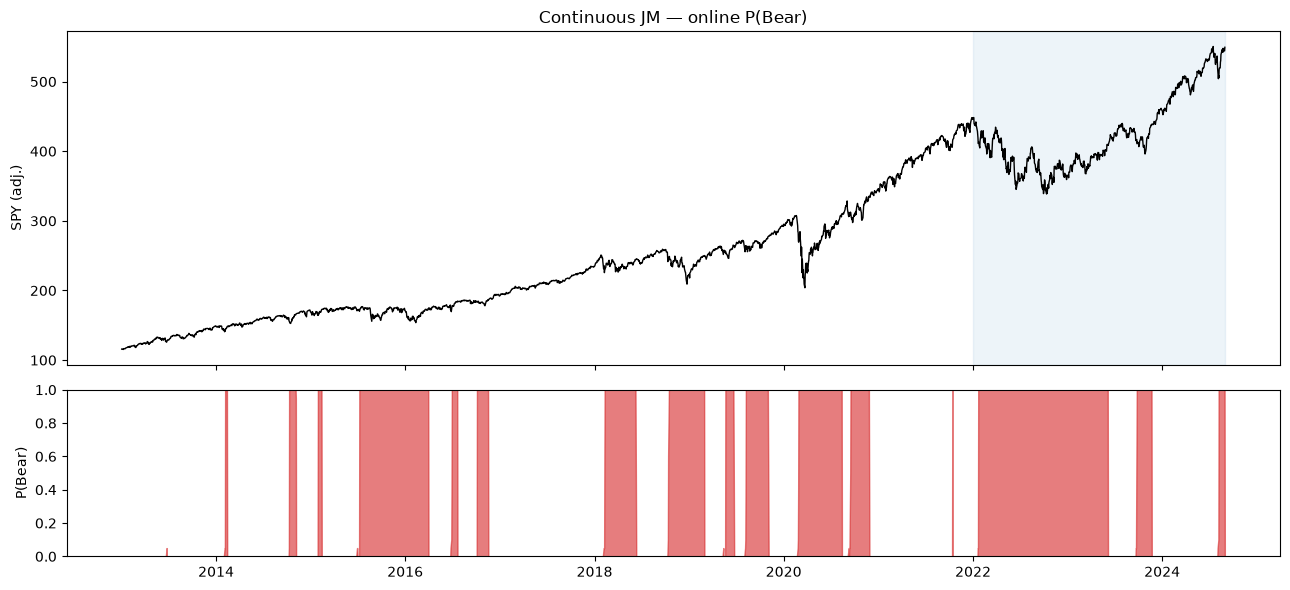

In [14]:
jmc = JumpModel(n_components=N_REGIMES, jump_penalty=JUMP_PENALTY, cont=True, random_state=0)
jmc.fit(X_train, ret_ser=excess.loc[X_train.index], sort_by="cumret")
proba_online = jmc.predict_proba_online(X_all)

fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
axes[0].plot(px["SPY"].loc[proba_online.index], color="black", lw=1)
axes[0].axvspan(pd.Timestamp(VAL_START), proba_online.index[-1], color="tab:blue", alpha=0.08)
axes[0].set_ylabel("SPY (adj.)")
axes[0].set_title("Continuous JM — online P(Bear)")
axes[1].fill_between(proba_online.index, proba_online.iloc[:, 1], color="tab:red", alpha=0.6)
axes[1].set_ylim(0, 1)
axes[1].set_ylabel("P(Bear)")
plt.tight_layout()

## Three regimes (for comparison with jrfm-13)

regime switches per year: 0.78


,Bull,Neutral,Bear
share of days,0.483,0.476,0.041
episodes,4.000,3.000,1.000
mean duration (days),273.500,359.667,94.000
median duration (days),291.000,439.000,94.000
SPY ann. ret,0.243,0.103,-0.005
SPY ann. vol,0.103,0.153,0.511
SPY Sharpe,2.338,0.624,-0.020
TLT ann. ret,0.005,0.080,0.362
TLT ann. vol,0.120,0.126,0.319
TLT Sharpe,0.019,0.575,1.120


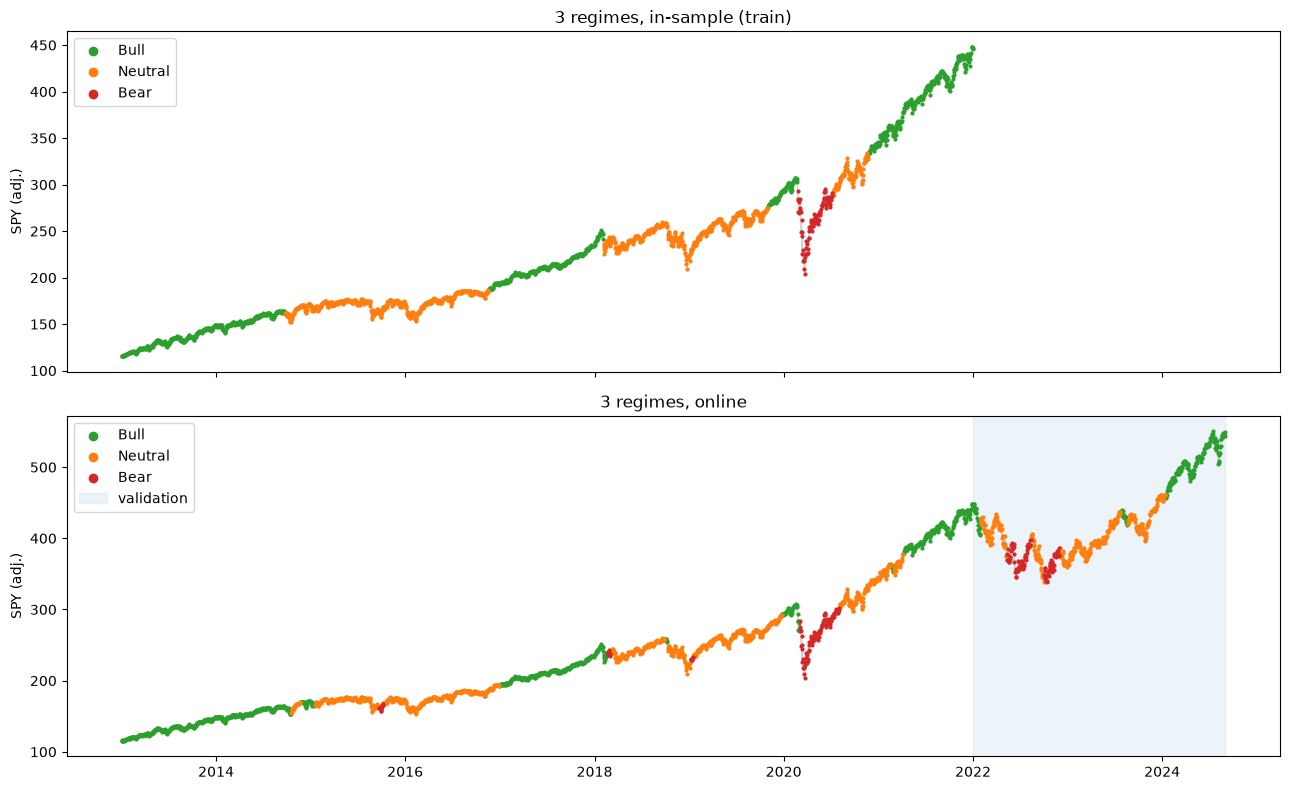

In [15]:
jm3 = JumpModel(n_components=3, jump_penalty=JUMP_PENALTY, cont=False, random_state=0)
jm3.fit(X_train, ret_ser=excess.loc[X_train.index], sort_by="cumret")
names3 = {0: "Bull", 1: "Neutral", 2: "Bear"}
on3 = jm3.predict_online(X_all)

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
plot_regimes(px["SPY"], jm3.labels_, "3 regimes, in-sample (train)", axes[0], names=names3)
plot_regimes(px["SPY"], on3, "3 regimes, online", axes[1], val_start=VAL_START, names=names3)
plt.tight_layout()

summary3 = regime_summary(jm3.labels_, rets)
summary3.columns = [names3[k] for k in range(3)]
summary3

## Notes / open points
- $\lambda$ is fixed at 50 here; the paper selects it by time-series cross-validation on the Sharpe ratio of a 0/1 strategy.
- The model is fitted once on the whole training window. A walk-forward refit (e.g. every 6 months, as in the paper) is the rigorous version.
- The continuous JM's probabilities are almost always 0 or 1, because the mode loss pushes them to the corners of the simplex. For a really soft gate, try `mode_loss=False`.
- 2 vs. 3 regimes: check whether the third regime is economically distinct (see the per-asset table) or just splits Bull.